# Synthetic MAGICAL-inspired target → Gaussian microscope image

A small forward check at **200 kV and 40,000×**. Start with a parallel circular
wave **at the specimen**, apply a simplified synthetic MAGICAL transmission
with the background waves and dark landmarks removed, then propagate its coherent Gaussian beamlets through the objective,
three intermediate lenses and projector. The illumination at the specimen is
prescribed; the condenser is therefore not part of this propagation.

The image plane is a plain coordinate grid: 256 × 256 points over 14.08 mm,
equivalent to 55 µm pitch. A 300 nm diameter illuminated area should become
12 mm across. We include the magnetic lenses' image rotation.

This tests ideal paraxial imaging of the **overview sample**, not atomic-resolution
contrast or a calibrated real instrument. The sample has both amplitude and phase;
at exact focus, an ideal unlimited-aperture microscope reproduces exit-wave
intensity, so pure phase structure does not generate intensity contrast here.

In [1]:
from pathlib import Path
from dataclasses import replace
from types import SimpleNamespace
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

from temgym_core.microscope_model import MicroscopeModel
from temgym_core.components import Plane
from temgym_core.ray import Ray
from temgym_core.run import run_to_end, solve_model_with_z
from temgym_core.multiscale_sample import MAGICALSampleAtlas, SampleView
from temgym_core.source import circular_input_wave
from temgym_core.evaluate import evaluate_gaussians

%matplotlib inline
# Works when launched from either the repository root or this notebook's folder.
repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/temgym_core").is_dir())
print("JAX devices:", jax.devices())

JAX devices: [CudaDevice(id=0)]


## Microscope and imaging condition

Use the positions and 40k operating point in `microscope.toml`. Refine only the
objective and first intermediate focal lengths locally, enforcing $A=40{,}000$
and $B=0$ in the co-rotating 2 × 2 ray matrix. The notebook does not write the
configuration. Lens currents retain their signs, which determine Larmor rotation.
All lens thicknesses and stigmators are zero for this ideal imaging check.

`column` below is the executable sample-to-image microscope model, with the
final `Plane` setting its observation position. The printed currents and focal
lengths describe this model, rather than measured hardware settings.

In [2]:
magnification = 40_000.0
beam_radius = 150e-9
waists = (2e-9, 1e-9)  # coarse and refined sample approximation
shape = (256, 256)
image_pitch = 55e-6
evaluation_method = "spatial"  # rebuild support bins on GPU for every render
evaluation_tiles = (16, 32)  # pixels, beams; benchmarked on the GH200 in float64

model = MicroscopeModel.from_toml(
    repo / "examples/microscope_models/microscope.toml",
    mode_names={"imaging.magnification": "mag"},
)
voltage = model.voltage
z_sample = model.auxiliary["sample"]["z"]
z_image = model.auxiliary["detector"]["z"]
lenses = [c for c in model.build_components({"mag": magnification})
          if z_sample < float(c.z) < z_image]
assert len(lenses) == 5
assert all(float(c.thickness) == 0 and
           float(c.stigmator_strength_x) == float(c.stigmator_strength_y) == 0
           for c in lenses)
f_initial = np.array([float(c.focal_length(voltage)) for c in lenses])

def scalar_transfer(focals):
    matrix, z = np.eye(2), z_sample
    for lens, focal in zip(lenses, focals):
        drift = np.array([[1., float(lens.z) - z], [0., 1.]])
        thin_lens = np.array([[1., 0.], [-1 / focal, 1.]])
        matrix = thin_lens @ drift @ matrix
        z = float(lens.z)
    return np.array([[1., z_image - z], [0., 1.]]) @ matrix

def focus_residual(log_scale):
    focals = f_initial.copy()
    focals[:2] *= np.exp(log_scale)
    matrix = scalar_transfer(focals)
    return [matrix[0, 0] / magnification - 1.,
            matrix[0, 1] / (magnification * 1e-3)]

fit = least_squares(focus_residual, np.zeros(2),
                    xtol=1e-14, ftol=1e-14, gtol=1e-14)
assert fit.success, fit.message
np.testing.assert_allclose(focus_residual(fit.x), 0., atol=1e-10)
focals = f_initial.copy()
focals[:2] *= np.exp(fit.x)
lenses = [replace(c, current=float(c.current) * np.sqrt(old / new))
          for c, old, new in zip(lenses, f_initial, focals)]
column = lenses + [Plane(z=z_image)]

# Independently differentiate the actual component pipeline in the lab frame.
probe = Ray(x=0., y=0., dx=0., dy=0., z=z_sample,
            pathlength=0., voltage=voltage)
matrix = np.asarray(solve_model_with_z(probe, column)[1][-1])
A, B = matrix[:2, :2], matrix[:2, 2:4]  # ordering is (x, y, dx, dy)
measured_magnifications = np.linalg.svd(A, compute_uv=False)
rotation_deg = np.degrees(np.arctan2(A[1, 0], A[0, 0]))
np.testing.assert_allclose(measured_magnifications, magnification, rtol=1e-9)
np.testing.assert_allclose(B, 0., atol=1e-10)

names = {float(c.z_position): c.name for c in model.lenses}
print(f"Voltage: {voltage / 1e3:.0f} kV; sample z: {z_sample:.6f} m")
print("Lens        z after sample [mm]   f [mm]     current [A]   turns")
for lens in lenses:
    print(f"{names[float(lens.z)]:10s}  {(float(lens.z)-z_sample)*1e3:12.4f}"
          f"       {float(lens.focal_length(voltage))*1e3:8.4f}"
          f"      {float(lens.current):9.6f}   {float(lens.turns):.0f}")
print(f"Image plane: {(z_image-z_sample)*1e3:.2f} mm after sample")
print(f"Measured magnifications: {measured_magnifications}; rotation: {rotation_deg:.3f}°")
print(f"max |B|: {np.abs(B).max():.2e} m")
print(f"Illuminated image diameter: {2*beam_radius*magnification*1e3:.2f} mm")
print(f"Image grid width: {shape[1]*image_pitch*1e3:.2f} mm")

Voltage: 200 kV; sample z: 0.325000 m
Lens        z after sample [mm]   f [mm]     current [A]   turns
Obj_post          2.3000         2.2719      -2.472521   3000
IL1             213.5240        18.3268       2.205678   3000
IL2             290.4802        18.7489       1.762284   2000
IL3             352.9802        32.8586       2.137981   2000
PL1             407.9835         2.2863      -3.500000   2000
Image plane: 718.75 mm after sample
Measured magnifications: [40000. 40000.]; rotation: -0.000°
max |B|: 1.81e-14 m
Illuminated image diameter: 12.00 mm
Image grid width: 14.08 mm


## Sample and coordinate grids

Use the atlas's global overview at approximately 0.9 nm knot spacing. Smaller
regional rasters keep setup light; the atomic-resolution regional views are not
used. Remove the sinusoidal background and Gaussian landmarks by setting their
phase and attenuation strengths to zero before rendering the atlas again.
The Si/SiGe layer boundaries, widths and interface smoothing are retained.
Keep this sample fixed while refining the Gaussian waist.

The nominal widths are **13 nm Si** and **10 nm SiGe**: at 40,000× these become
**0.52 mm** and **0.40 mm**, respectively (a **0.92 mm repeat**). These widths
provide the magnification reference without the extra test patterns.

The reference is evaluated at the object coordinates obtained from the measured
optical transfer, $\mathbf{x}_s=A^{-1}\mathbf{x}_i$. This accounts for rotation
without interpolating or resizing the computed image.

In [3]:
atlas = MAGICALSampleAtlas.nominal(
    shape_yx=(384, 384), region_shape_yx=(128, 128),
    authoritative_multilayer_shape_yx=(256, 256),
    max_levels=3, voltage=voltage,
)
# Remove both phase and amplitude contributions from the background/landmarks.
# Keep the named feature records required by the certificate schema.
original_certificate = atlas.certificate
clean_certificate = replace(
    original_certificate,
    features=tuple(replace(feature, phase_amplitude_rad=0., log_amplitude_depth=0.)
                   for feature in original_certificate.features),
)
assert clean_certificate.layer_boundaries == original_certificate.layer_boundaries
assert all(f.phase_amplitude_rad == f.log_amplitude_depth == 0.
           for f in clean_certificate.features)
atlas = MAGICALSampleAtlas.from_certificate(
    clean_certificate, shape_yx=(384, 384), region_shape_yx=(128, 128),
    authoritative_multilayer_shape_yx=(256, 256), max_levels=3,
    global_support_margin_m=atlas.global_support_margin_m,
)
sample = SampleView.from_level(atlas.pyramid.levels[0], z=z_sample)
widths = np.array([atlas.certificate.silicon_layer_width_m,
                   atlas.certificate.silicon_germanium_layer_width_m])
np.testing.assert_allclose(widths, [13e-9, 10e-9], rtol=1e-12, atol=0.)
print("Si / SiGe widths [nm]:", widths * 1e9)
print("Expected image widths [mm]:", widths * magnification * 1e3)
print("Expected image repeat [mm]:", widths.sum() * magnification * 1e3)

def coordinate_grid(shape, pitch):
    x = (np.arange(shape[1]) - (shape[1] - 1) / 2) * pitch
    y = (np.arange(shape[0]) - (shape[0] - 1) / 2) * pitch
    xx, yy = np.meshgrid(x, y, indexing="xy")
    return SimpleNamespace(shape=shape, coords=jnp.asarray(np.stack((xx, yy), -1).reshape(-1, 2)))

image_grid = coordinate_grid(shape, image_pitch)
object_grid = coordinate_grid(shape, image_pitch / magnification)
mapped_grid = SimpleNamespace(
    shape=shape, coords=jnp.asarray(np.asarray(image_grid.coords) @ np.linalg.inv(A).T),
)
actions = np.asarray(sample.evaluate_actions(mapped_grid.coords)).reshape(*shape, 2)
transmission_intensity = np.exp(2 * actions[..., 1])
print("Sample knot spacing [nm]:", np.array(atlas.pyramid.levels[0].pixel_size_yx_m) * 1e9)
print("Sample-equivalent image spacing [nm]:", image_pitch / magnification * 1e9)

Si / SiGe widths [nm]: [13. 10.]
Expected image widths [mm]: [0.52 0.4 ]
Expected image repeat [mm]: 0.92


Sample knot spacing [nm]: [0.91099854 0.91099854]
Sample-equivalent image spacing [nm]: 1.3750000000000002


## Propagate the Gaussian wave and check the image

For each waist, compare three intensities on corresponding coordinates:

1. Direct reference: $|\psi_{\rm in}(\mathbf{x}_s)|^2|t(\mathbf{x}_s)|^2$.
2. Reconstructed Gaussian exit wave immediately after the sample.
3. Gaussian image propagated through every lens and drift, multiplied by
   $|\det A|=M^2$ to account for the expanded area.

No fitted intensity normalization is used. This separates error from the local
quadratic sample approximation from error accumulated during lens propagation.
The narrower basis should improve the sample approximation. `spatial` builds
support bins and sums neighbouring Gaussians on the GPU for each call, falling
back to the dense evaluator for broad beams and a portable JAX scan on CPU; the refined
run has about 159,000 beamlets and takes longer on CPU.

The spatial backend uses float64 and a Gaussian-envelope cutoff of `1e-12`.
Bins are rebuilt on the device, so changes in position or width do not reuse a
stale neighbour list. It is a forward-only backend: use `scan` when automatic
differentiation is needed. The dense comparison and timings below check the
current scene. See `GAUSSIAN_FORWARD_SPEED.md` and `benchmark_gaussian_forward.py`.


In [4]:
apply_sample = jax.jit(lambda beam: sample(beam))
propagate = jax.jit(lambda beam: run_to_end(beam, column))

def intensity(beam, grid):
    field = np.asarray(evaluate_gaussians(
        beam, grid, method=evaluation_method, tile_pixels=evaluation_tiles[0],
        tile_beams=evaluation_tiles[1],
    ))
    assert np.isfinite(field).all()
    return np.abs(field)**2

def relative_l2(actual, expected):
    return np.linalg.norm(actual - expected) / np.linalg.norm(expected)

results = []
print("waist [nm]   beamlets   sample error   propagation error   total image error")
for waist in waists:
    beam_in = circular_input_wave(
        aperture_radius=beam_radius, waist=waist, voltage=voltage,
        z0=z_sample, overlap_factor=1.5,
    )
    beam_exit = apply_sample(beam_in)
    beam_out = propagate(beam_exit)
    incoming = intensity(beam_in, mapped_grid)
    reference = incoming * transmission_intensity
    exit_intensity = intensity(beam_exit, mapped_grid)
    image_intensity = intensity(beam_out, image_grid)
    scaled_image = image_intensity * abs(np.linalg.det(A))
    errors = (relative_l2(exit_intensity, reference),
              relative_l2(scaled_image, exit_intensity),
              relative_l2(scaled_image, reference))
    results.append(errors)
    print(f"{waist*1e9:10.2f}   {beam_in.x.size:8d}   "
          f"{errors[0]:12.3%}   {errors[1]:17.6%}   {errors[2]:16.3%}")
    assert errors[1] < 1e-4, "Optical propagation does not reproduce the magnified exit wave"

# These are checks of this overview scene, not universal Gaussian error bounds.
assert results[-1][2] < 0.01, "Refined image differs from direct transmission by more than 1%"
assert results[-1][2] < results[0][2], "Narrower beamlets did not improve the sample approximation"
interior = (np.linalg.norm(np.asarray(mapped_grid.coords), axis=1)
            < beam_radius - 3*waists[0]).reshape(shape)
correlation = np.corrcoef(scaled_image[interior], reference[interior])[0, 1]
assert correlation > 0.99
print(f"Image/reference correlation inside the illuminated disk: {correlation:.6f}")
print("PASS: magnification, focus, Gaussian transport, sample refinement and image agreement")

waist [nm]   beamlets   sample error   propagation error   total image error


      2.00      39761         0.920%           0.000239%             0.920%


      1.00     159044         0.256%           0.000049%             0.256%
Image/reference correlation inside the illuminated disk: 0.999496
PASS: magnification, focus, Gaussian transport, sample refinement and image agreement


## Dense comparison and forward timings

Compare the complex fields as well as the sample image. Timings include the
sample, `run_to_end`, GPU bin rebuilding and one image reconstruction, after
compilation. They exclude plotting and source construction.

In [5]:
from time import perf_counter

spatial_field = np.asarray(evaluate_gaussians(beam_out, image_grid, method="spatial", tile_beams=32))
dense_field = np.asarray(evaluate_gaussians(beam_out, image_grid, method="gpu_kernel", tile_beams=32))
field_error = relative_l2(spatial_field, dense_field)
tail_bound = 1e-12 * np.abs(np.asarray(beam_out.amplitude)).sum()
assert field_error < 1e-9
assert np.max(abs(spatial_field - dense_field)) < tail_bound + 1e-14
print(f"Spatial / dense complex-field error: {field_error:.3e}")

def forward_time_ms(method, repeats=5):
    def forward():
        output_beams = propagate(apply_sample(beam_in))
        field = evaluate_gaussians(output_beams, image_grid, method=method, tile_beams=32)
        return jnp.abs(field)**2
    jax.block_until_ready(forward())
    durations = []
    for _ in range(repeats):
        start = perf_counter()
        jax.block_until_ready(forward())
        durations.append((perf_counter() - start) * 1e3)
    return np.median(durations)

dense_ms = forward_time_ms("gpu_kernel")
spatial_ms = forward_time_ms("spatial")
print(f"Dense complete forward: {dense_ms:.2f} ms")
print(f"Spatial complete forward, including bin rebuild: {spatial_ms:.2f} ms")
print(f"Speedup over the tuned dense kernel: {dense_ms / spatial_ms:.1f}×")

Spatial / dense complex-field error: 5.376e-16


Dense complete forward: 141.53 ms
Spatial complete forward, including bin rebuild: 7.27 ms
Speedup over the tuned dense kernel: 19.5×


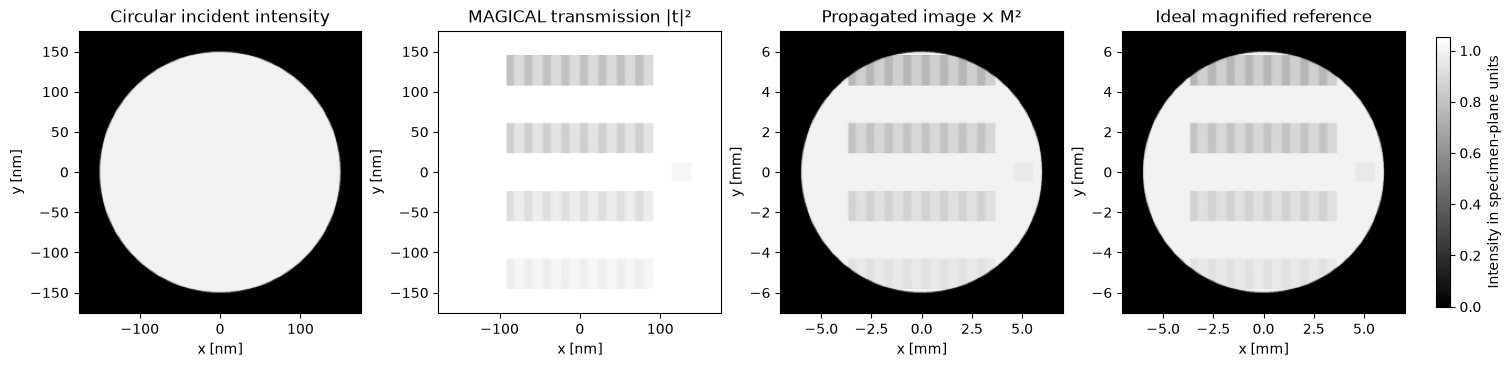

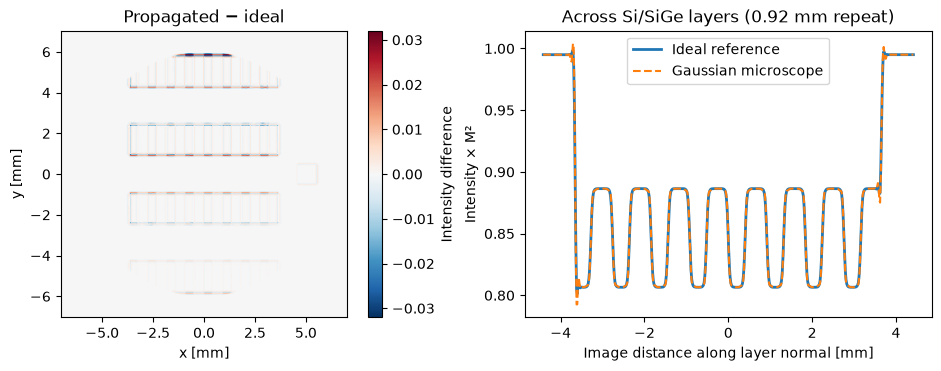

In [6]:
# The last loop iteration supplies the refined image. Shared color limits matter.
input_plot = intensity(beam_in, object_grid)
sample_plot = np.exp(2 * np.asarray(sample.evaluate_actions(object_grid.coords))[:, 1]).reshape(shape)
width_nm = shape[1] * image_pitch / magnification * 1e9
width_mm = shape[1] * image_pitch * 1e3
extent_nm = np.array([-1, 1, -1, 1]) * width_nm / 2
extent_mm = np.array([-1, 1, -1, 1]) * width_mm / 2
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), constrained_layout=True)
vmax = max(reference.max(), scaled_image.max(), input_plot.max())
panels = [
    (input_plot, extent_nm, "Circular incident intensity", "nm"),
    (sample_plot, extent_nm, "MAGICAL transmission |t|²", "nm"),
    (scaled_image, extent_mm, "Propagated image × M²", "mm"),
    (reference, extent_mm, "Ideal magnified reference", "mm"),
]
for ax, (values, extent, title, unit) in zip(axes, panels):
    im = ax.imshow(values, origin="lower", extent=extent, cmap="gray",
                   vmin=0, vmax=vmax if unit == "mm" or values is input_plot else 1)
    ax.set(title=title, xlabel=f"x [{unit}]", ylabel=f"y [{unit}]")
fig.colorbar(im, ax=list(axes[2:]), label="Intensity in specimen-plane units", shrink=0.75)
plt.show()

difference = scaled_image - reference
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
limit = np.max(np.abs(difference))
im = axes[0].imshow(difference, origin="lower", extent=extent_mm,
                    cmap="RdBu_r", vmin=-limit, vmax=limit)
axes[0].set(title="Propagated − ideal", xlabel="x [mm]", ylabel="y [mm]")
fig.colorbar(im, ax=axes[0], label="Intensity difference")
# Plot along a multilayer patch, following its orientation through the optics.
region = next(r for r in atlas.certificate.regions if r.name == "multilayer_region_3")
profile_x = np.linspace(-0.6 * region.size_xy_m[0], 0.6 * region.size_xy_m[0], 512)
profile_xy = np.column_stack((profile_x + region.centre_xy_m[0],
                              np.full_like(profile_x, region.centre_xy_m[1])))
profile_object_grid = SimpleNamespace(shape=(1, len(profile_x)), coords=jnp.asarray(profile_xy))
profile_image_grid = SimpleNamespace(shape=(1, len(profile_x)), coords=jnp.asarray(profile_xy @ A.T))
profile_transmission = np.exp(2 * np.asarray(sample.evaluate_actions(profile_object_grid.coords))[:, 1])
profile_reference = intensity(beam_in, profile_object_grid).ravel() * profile_transmission
profile_image = intensity(beam_out, profile_image_grid).ravel() * abs(np.linalg.det(A))
image_distance_mm = profile_x * np.linalg.norm(A[:, 0]) * 1e3
axes[1].plot(image_distance_mm, profile_reference, label="Ideal reference", lw=2)
axes[1].plot(image_distance_mm, profile_image, "--", label="Gaussian microscope")
axes[1].set(title="Across Si/SiGe layers (0.92 mm repeat)",
            xlabel="Image distance along layer normal [mm]", ylabel="Intensity × M²")
axes[1].legend()
plt.show()

The image should show the same illuminated MAGICAL features, enlarged by 40,000×
and rotated by the magnetic lenses. Remaining differences are concentrated near
sharp specimen features, where a finite beamlet's quadratic sample expansion is
least accurate. The waist-refinement table makes that limitation visible.

This is a check at one focused operating point with a coherent input wave, ideal
lenses, and no objective aperture. It does not validate aberrations, partial
coherence, atomic-resolution scattering, detector response, or the full range of
microscope settings. The numerical assertions describe the fixed example above;
changing the sample, waist, grid or lens settings may require finer sampling.

## Sample provenance and references

This notebook starts from `MAGICALSampleAtlas.nominal()` in
`src/temgym_core/multiscale_sample.py`. Its metadata explicitly says
`certificate_source="nominal synthetic certificate"`; no measured specimen
certificate was supplied. The target is useful for a numerical propagation test,
but its name does not establish physical fidelity to a commercial MAG*I*CAL sample.

The [Norrox MAG*I*CAL instruction manual, hosted by Electron Microscopy Sciences](https://www.emsdiasum.com/docs/technical/datasheet/MAGICALinstructionbookcolor.pdf)
describes four groups of five approximately 10 nm SiGe layers alternating with
approximately 13 nm Si layers (page 3). The example dimensions span about 5.21 µm,
with group separations around 1.2 µm (page 15); the central perforation is about
0.1 mm (pages 1 and 6). These are nominal/example dimensions, not the calibration
certificate for a particular specimen. See also the
[Ted Pella MAG*I*CAL description and micrographs](https://www.tedpella.com/Calibration_html/675mag.aspx).

In contrast, this code places four rectangular patches in a 352 nm field,
uses eight SiGe/Si repeats per patch and a 40 nm central hole. The nominal atlas
also defines sinusoidal textures and three asymmetric Gaussian landmarks; this
notebook zeros both their phase and attenuation strengths and re-renders the
sample, so those features are absent. The layer widths and boundaries are retained.
The sample still assigns
phase and attenuation strengths directly, with increasing contrast across the
four patches. Those are synthetic test choices; they are not obtained from the
manufacturer's geometry, a measured image, or a Si/SiGe scattering calculation.
Smooth boundaries support the local Gaussian action expansion. Magnification
is referenced to the retained 13 nm Si and 10 nm SiGe widths (23 nm repeat).

Consequently, the reported image errors validate propagation of this prescribed
complex transmission. They do not validate the appearance or scattering physics
of a real MAG*I*CAL specimen. A realistic example should use a local crop of the
actual multilayer geometry and separately justify its transmission model.
